# What a year of Spotify says about me

An end-to-end data analytics project on my own Spotify listening history: loading, inspection, cleaning, feature engineering, analysis and findings. Built with Python, pandas, matplotlib and seaborn.

**Data:** Spotify basic account export (streaming history), 6 Oct 2025 to 6 Oct 2026, 23,705 plays across 3 JSON files.

**Questions**
1. **How picky am I as a listener?** What share of my plays do I skip, and does it change over time?
2. **Am I a loyalist or an explorer?** How concentrated is my listening?
3. **How consistently do I listen?** What are my longest streak and longest gap?
4. **How often does my listening pattern change, and what stays constant?** How much does my top 10 change month to month, and how adventurous am I?

## Data dictionary

Each row is **one play of one song**.

| Column | Meaning | Unit / format |
|---|---|---|
| `endTime` | The moment the play ended (song finished, skipped, or stopped) | Date and time in **UTC**. India time is UTC+5:30 |
| `artistName` | The artist Spotify recorded for the track | Text |
| `trackName` | The title of the song | Text. The same title can belong to different artists, so I always pair it with `artistName` |
| `msPlayed` | How long the song actually played during that row (not the song's full length) | Milliseconds. Divide by 60,000 for minutes |

**Limitations of the export:** there is no start time, no song length, and no genre, device or playlist information.


In [1]:
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [2]:
paths = sorted(glob.glob("StreamingHistory_music_?.json"))
print("Files found:", paths)

dfs = []
for p in paths:
    part = pd.read_json(p)
    print(f"{p}: {len(part)} rows")
    dfs.append(part)

df = pd.concat(dfs, ignore_index=True)
print("Combined total:", len(df))



Files found: ['StreamingHistory_music_0.json', 'StreamingHistory_music_1.json', 'StreamingHistory_music_2.json']
StreamingHistory_music_0.json: 10000 rows
StreamingHistory_music_1.json: 10000 rows
StreamingHistory_music_2.json: 3705 rows
Combined total: 23705


# DATA INSPECTION

In [3]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23705 entries, 0 to 23704
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   endTime     23705 non-null  str  
 1   artistName  23705 non-null  str  
 2   trackName   23705 non-null  str  
 3   msPlayed    23705 non-null  int64
dtypes: int64(1), str(3)
memory usage: 740.9 KB


In [4]:
times = pd.to_datetime(df["endTime"])
print("\nEarliest:", times.min())
print("Latest:  ", times.max())



Earliest: 2025-10-06 04:36:00
Latest:   2026-10-06 17:11:00


In [5]:
blank_artist = df["artistName"].isna() | (df["artistName"].str.strip() == "")
print("\nBlank artist rows:", blank_artist.sum())
print("Unique tracks with a blank artist:", df.loc[blank_artist, "trackName"].nunique())
print("Missing track names:", (df["trackName"].isna() | (df["trackName"].str.strip() == "")).sum())


Blank artist rows: 0
Unique tracks with a blank artist: 0
Missing track names: 0


In [6]:
print("\nDuplicate rows:", df.duplicated().sum())
print("Plays under 30 sec:", (df["msPlayed"] < 30000).sum())
print("Plays of 0 ms:", (df["msPlayed"] == 0).sum())
print("Longest play (min):", round(df["msPlayed"].max() / 60000, 1))


Duplicate rows: 0
Plays under 30 sec: 7073
Plays of 0 ms: 188
Longest play (min): 28.8


In [7]:
print("\nUnique artists:", df["artistName"].nunique())
print("Unique tracks:", df["trackName"].nunique())


Unique artists: 1389
Unique tracks: 2810


### Inspection summary

| Check | Result |
|---|---|
| Size | 23,705 rows (10,000 + 10,000 + 3,705), 4 columns |
| Time range (UTC) | 2025-10-06 04:36 to 2026-10-06 17:11 (first and last days are partial) |
| Variety | 1,389 unique artists, 2,810 unique tracks |
| Duplicate rows | 0 |
| Missing artist or track names | 0 |
| Longest single play | 28.8 minutes (a real long track, so no outliers) |
| **Plays under 30 seconds** | **7,073 (about 30%)**, including 188 plays of exactly 0 ms |

**Issue found:** nearly a third of plays are skips. They would distort play counts and streak days, so they are removed in the cleaning step. Spotify itself counts a stream from 30 seconds.

# DATA CLEANING

In [8]:
df_clean = df.copy()

df_clean["endTime"] = (
    pd.to_datetime(df_clean["endTime"])
    .dt.tz_localize("UTC")
    .dt.tz_convert("Asia/Kolkata")
)
print("converted")

converted


In [9]:
before_artists = df_clean["artistName"].copy()
before_tracks = df_clean["trackName"].copy()
df_clean["artistName"] = df_clean["artistName"].str.strip()
df_clean["trackName"] = df_clean["trackName"].str.strip()
print("Artist names changed by trimming:", (before_artists != df_clean["artistName"]).sum())
print("Track names changed by trimming:", (before_tracks != df_clean["trackName"]).sum())


Artist names changed by trimming: 0
Track names changed by trimming: 0


In [10]:
rows_before = len(df_clean)
df_clean = df_clean[df_clean["msPlayed"] >= 30000].reset_index(drop=True)

In [11]:
print("\nRows before:", rows_before)
print("Rows after: ", len(df_clean))
print("Removed:    ", rows_before - len(df_clean),
      f"({(rows_before - len(df_clean)) / rows_before:.1%})")
print("Date range (IST):", df_clean["endTime"].min(), "to", df_clean["endTime"].max())


Rows before: 23705
Rows after:  16632
Removed:     7073 (29.8%)
Date range (IST): 2025-10-06 10:06:00+05:30 to 2026-10-06 22:41:00+05:30


In [12]:
import re

def norm(s):
    # lowercase, drop spaces and punctuation; fall back to the original if nothing is left
    return re.sub(r"[^a-z0-9]+", "", s.lower()) or s.lower()

# 1. Artist names that differ only by case, spaces or punctuation
art = df_clean.groupby("artistName").size().reset_index(name="plays")
art["key"] = art["artistName"].map(norm)
dup_art = art[art.duplicated("key", keep=False)].sort_values(["key", "plays"], ascending=[True, False])
print("Artist spelling-variant groups:", dup_art["key"].nunique())
print(dup_art.head(20).to_string(index=False))

# 2. Same artist, track titles that differ only by case or punctuation
trk = df_clean.groupby(["artistName", "trackName"]).size().reset_index(name="plays")
trk["key"] = trk["artistName"] + "|" + trk["trackName"].map(norm)
dup_trk = trk[trk.duplicated("key", keep=False)].sort_values("key")
print("\nTrack-title variant groups (same artist):", dup_trk["key"].nunique())
print(dup_trk[["artistName", "trackName", "plays"]].head(20).to_string(index=False))

# 3. Same title used by different artists
trk["tkey"] = trk["trackName"].map(norm)
shared = trk.groupby("tkey").agg(example=("trackName", "first"), artists=("artistName", "nunique"), plays=("plays", "sum"))
shared = shared[shared["artists"] > 1].sort_values("plays", ascending=False)
print("\nTitles used by more than one artist:", len(shared))
print(shared.head(10).to_string())

Artist spelling-variant groups: 0
Empty DataFrame
Columns: [artistName, plays, key]
Index: []

Track-title variant groups (same artist): 3
artistName                                 trackName  plays
 Green Day            Wake Me Up When September Ends      3
 Green Day            Wake Me up When September Ends     20
     THIRD                เตือนแล้วนะ (Love Warning)     49
     THIRD เตือนแล้วนะ (Love Warning) - ดนตรีฝึกร้อง      1
    Yiruma                        River Flows In You      6
    Yiruma                        River Flows in You      1

Titles used by more than one artist: 47
                                           example  artists  plays
tkey                                                              
dinamuli                                Di Na Muli        3    506
september                                September        2    148
sinkingtown                           Sinking Town        5    118
sorry                                        Sorry        2     7

In [13]:
# Merge title variants for the same artist (the most-played spelling wins)
fixes = [
    ("Green Day", "wake me up when september ends"),
    ("Yiruma", "river flows in you"),
]

for artist, key in fixes:
    # lowercase and collapse extra spaces so hidden differences still match
    cleaned = df_clean["trackName"].str.lower().str.split().str.join(" ")
    mask = (df_clean["artistName"] == artist) & (cleaned == key)
    keep = df_clean.loc[mask, "trackName"].value_counts().index[0]
    changed = (df_clean.loc[mask, "trackName"] != keep).sum()
    df_clean.loc[mask, "trackName"] = keep
    print(f"{artist}: {mask.sum()} plays now share one title ({changed} rows changed)")

print("\nUnique tracks now:", df_clean[["artistName", "trackName"]].drop_duplicates().shape[0])

Green Day: 23 plays now share one title (3 rows changed)
Yiruma: 7 plays now share one title (1 rows changed)

Unique tracks now: 1813


### Cleaning summary

I worked on a copy (`df_clean`) so the raw table (`df`) stays intact.

**Steps**
1. Converted `endTime` from text to a real date and from UTC to India time (UTC+5:30), so days and months match my own calendar.
2. Trimmed stray spaces from artist and track names.
3. Removed plays under 30 seconds: **23,705 to 16,632 rows (7,073 removed, 29.8%)**.
4. Merged title variants of the same song by the same artist (2 songs, 30 plays), e.g. differences in capitalization or spacing.

**Checked, nothing to fix:** duplicate rows (0), missing values (0), outliers (none), artist spelling variants (0).

**Decisions**
- A song is identified by **artist + track together**, never by title alone. 47 titles are shared by different artists and are kept as separate songs.
- Different versions of a song (remastered, live) are counted as separate recordings.
- Date range after cleaning (India time): 2025-10-06 10:06 to 2026-10-06 22:41. The first and last days are partial.
- Q1 uses the **raw** table (to measure skips). Q2 to Q4 use the **cleaned** table.

# FEATURE ENGINEERING


In [14]:
df_clean["date"] = df_clean["endTime"].dt.date

# Year-month label, like 2026-03
df_clean["month"] = df_clean["endTime"].dt.strftime("%Y-%m")

# Listening time in minutes
df_clean["minutes"] = df_clean["msPlayed"] / 60000

# One label per song: artist + track together, so same-title songs stay separate
df_clean["song"] = df_clean["artistName"] + " - " + df_clean["trackName"]

In [15]:
print("Rows:", len(df_clean), "(should still be 16632)")
print("Distinct listening days:", df_clean["date"].nunique())
print("Months covered:", df_clean["month"].nunique())
print("Unique songs:", df_clean["song"].nunique())
print("Total listening time (hours):", round(df_clean["minutes"].sum() / 60, 1))

# Plays per month (partial months show up as small numbers)
print(df_clean["month"].value_counts().sort_index())

df_clean.dtypes

Rows: 16632 (should still be 16632)
Distinct listening days: 356
Months covered: 13
Unique songs: 1813
Total listening time (hours): 895.8
month
2025-10    1509
2025-11     695
2025-12    1225
2026-01    1031
2026-02    1414
2026-03    1817
2026-04    2134
2026-05    1827
2026-06    1432
2026-07    1221
2026-08    1188
2026-09     954
2026-10     185
Name: count, dtype: int64


endTime       datetime64[us, Asia/Kolkata]
artistName                             str
trackName                              str
msPlayed                             int64
date                                object
month                                  str
minutes                            float64
song                                   str
dtype: object

### Feature engineering summary

I added four helper columns to `df_clean`, so each question can be answered directly. The row count stays at **16,632**.

| New column | What it holds | Used for |
|---|---|---|
| `date` | Calendar day in India time, without the clock time | Streaks and gaps (Q3) |
| `month` | Year and month label, like `2026-03` | Month-by-month comparisons (Q4) |
| `minutes` | `msPlayed` converted to minutes | Listening time and artist shares (Q2, Q4) |
| `song` | Artist and track joined into one label | Keeping songs with the same title by different artists apart |

**What the new columns show**
- **895.8 hours** of real listening in total.
- **356 distinct listening days** across **13 calendar months**.
- **1,813 unique songs** after cleaning, which is far fewer than the 2,810 track titles in the raw data, because many titles were only ever skipped.

**Notes**
- `date` and `month` use India time, so a late-night play counts toward the right day.
- October 2025 covers 26 days and October 2026 covers only 6 days, so monthly counts for those two months are smaller. Month-to-month comparisons account for this where noted.

# DATA ANALYSIS

# Q1  How picky am I as a listener?


   
 i) What share of my plays do I skip?
 ii) Does my skip rate change over time?

In [16]:
raw = df[["endTime", "msPlayed"]].copy()
raw["endTime"] = pd.to_datetime(raw["endTime"]).dt.tz_localize("UTC").dt.tz_convert("Asia/Kolkata")
raw["month"] = raw["endTime"].dt.strftime("%Y-%m")
raw["skipped"] = raw["msPlayed"] < 30000   # a skip = under 30 seconds

In [17]:
total = len(raw)
skips = int(raw["skipped"].sum())
skip_rate = skips / total
print(f"Total plays: {total:,}")
print(f"Skipped (under 30 sec): {skips:,} ({skip_rate:.1%})")
print(f"Real plays: {total - skips:,} ({1 - skip_rate:.1%})")

Total plays: 23,705
Skipped (under 30 sec): 7,073 (29.8%)
Real plays: 16,632 (70.2%)


In [18]:
buckets = pd.cut(raw.loc[raw["skipped"], "msPlayed"] / 1000,
                 bins=[-0.1, 0, 5, 10, 20, 30],
                 labels=["0 sec", "1-5 sec", "6-10 sec", "11-20 sec", "21-30 sec"])
print("\nSkips by how long I listened:")
print(buckets.value_counts().sort_index())



Skips by how long I listened:
msPlayed
0 sec         188
1-5 sec      4277
6-10 sec     1081
11-20 sec     948
21-30 sec     579
Name: count, dtype: int64


In [19]:
monthly = raw.groupby("month").agg(plays=("skipped", "size"), skips=("skipped", "sum"))
monthly["skip_rate"] = monthly["skips"] / monthly["plays"]
print("\n", monthly.round(3))
print("\nHighest skip rate:", monthly["skip_rate"].idxmax(), f"({monthly['skip_rate'].max():.1%})")
print("Lowest skip rate: ", monthly["skip_rate"].idxmin(), f"({monthly['skip_rate'].min():.1%})")


          plays  skips  skip_rate
month                           
2025-10   1816    307      0.169
2025-11    879    184      0.209
2025-12   1562    337      0.216
2026-01   1278    247      0.193
2026-02   1878    464      0.247
2026-03   2360    543      0.230
2026-04   2931    797      0.272
2026-05   2938   1111      0.378
2026-06   2058    626      0.304
2026-07   1879    658      0.350
2026-08   2342   1154      0.493
2026-09   1471    517      0.351
2026-10    313    128      0.409

Highest skip rate: 2026-08 (49.3%)
Lowest skip rate:  2025-10 (16.9%)


Skipped: 7073 | Real plays: 16632


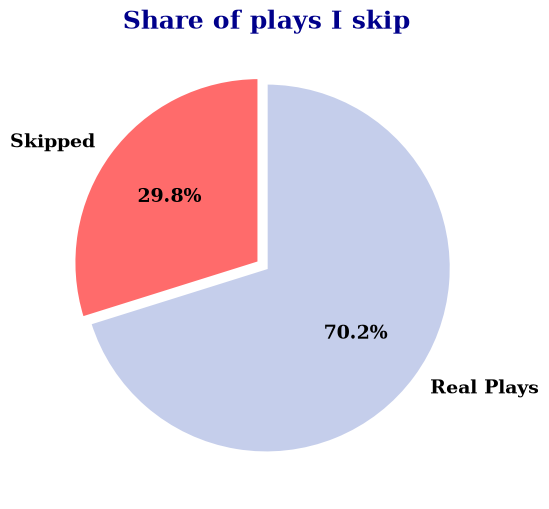

In [20]:
skip_count = int((raw["msPlayed"] < 30000).sum())
real_count = int((raw["msPlayed"] >= 30000).sum())
print("Skipped:", skip_count, "| Real plays:", real_count)   # expect 7073 and 16632

labels = ["Skipped", "Real Plays"]
sizes = [skip_count, real_count]

sns.set_theme(font="serif")

colors = ["#FF6B6B", "#C5CEEB"]
plt.figure(figsize=(6, 6))
plt.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.05, 0],
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 14, "color": "black", "fontweight": "bold"},
)
plt.title("Share of plays I skip", fontsize=18, fontweight="bold", color="darkblue")
plt.show()

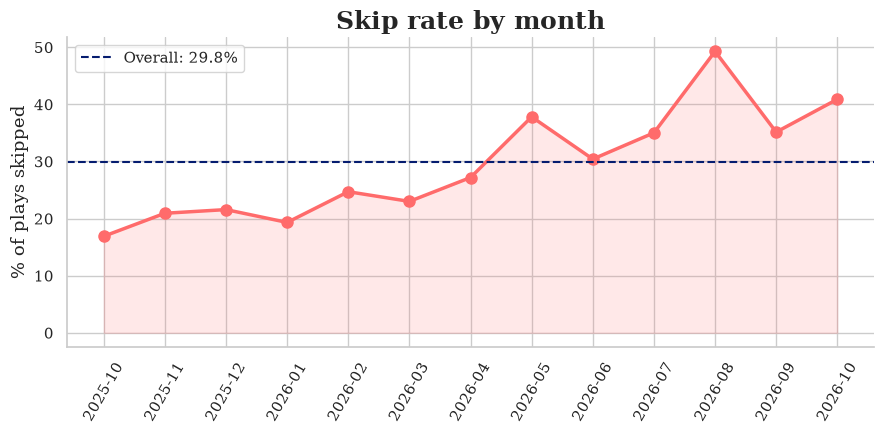

In [21]:
sns.set_theme(style="whitegrid", font="serif")

fig, ax = plt.subplots(figsize=(9, 4.5))

x = monthly.index
y = monthly["skip_rate"] * 100

ax.plot(x, y, marker="o", markersize=8, linewidth=2.5, color="#FF6B6B")
ax.fill_between(x, y, alpha=0.15, color="#FF6B6B")   
ax.axhline(skip_rate * 100, linestyle="--", linewidth=1.5, color= "#051C6F",
           label=f"Overall: {skip_rate:.1%}")

ax.set_title("Skip rate by month", fontsize=18, fontweight="bold")
ax.set_ylabel("% of plays skipped", fontsize=13)
ax.tick_params(axis="x", rotation=60, labelsize=11)
ax.tick_params(axis="y", labelsize=11)
ax.legend(frameon=True, fontsize=11)

sns.despine()   # remove top/right borders
plt.tight_layout()
plt.show()

In [22]:
print("skips:", skips, "| total:", total, "| skip_rate:", round(skip_rate, 3))


skips: 7073 | total: 23705 | skip_rate: 0.298


## Q1. How picky am I as a listener?

**Definition:** a "skip" is a play of under 30 seconds. This question uses the raw data (23,705 plays), because the cleaned table has the skips removed.

### Finding 1: Overall skip rate
I skipped **7,073 of 23,705 plays (29.8%)**, which is nearly 1 in 3.
Of those skips, 63% were instant (0 to 5 seconds).

### Finding 2: Skip rate over time
My skip rate rose from about **17% in October 2025** to a peak of about **49% in August 2026**. I went from skipping roughly 1 in 6 plays to about 1 in 2.
- The overall average (29.8%) hides this trend.
- October 2026 covers only 6 days, so its value is noisy.

**Takeaway:** I'm getting pickier over the year, or I'm sampling more new music and abandoning more of it.

# Q2. Am I a loyalist or an explorer?
i) How concentrated is my listening?


In [23]:
# Minutes per artist, biggest first
artist_minutes = df_clean.groupby("artistName")["minutes"].sum().sort_values(ascending=False)
total_min = artist_minutes.sum()
n_artists = len(artist_minutes)
cum_share = artist_minutes.cumsum() / total_min   # running share of total listening time

print(f"Artists with at least one real play: {n_artists:,}")
print(f"Total listening time: {total_min / 60:,.1f} hours")

# How concentrated is my listening?
print("\nShare of total listening time going to my top artists:")
for k in [1, 5, 10, 50, 100]:
    print(f"  Top {k:>3}: {cum_share.iloc[k - 1]:.1%}")

n50 = int((cum_share < 0.5).sum()) + 1
n80 = int((cum_share < 0.8).sum()) + 1
print(f"\nArtists needed to cover 50% of my listening: {n50}")
print(f"Artists needed to cover 80% of my listening: {n80}")

# The long tail: artists I only ever played once
plays_per_artist = df_clean.groupby("artistName").size()
one_play = plays_per_artist[plays_per_artist == 1].index
print(f"\nArtists played only once: {len(one_play):,} ({len(one_play) / n_artists:.1%} of all artists)")
print(f"Their share of my listening time: {artist_minutes[one_play].sum() / total_min:.1%}")

Artists with at least one real play: 883
Total listening time: 895.8 hours

Share of total listening time going to my top artists:
  Top   1: 4.2%
  Top   5: 16.6%
  Top  10: 27.4%
  Top  50: 62.6%
  Top 100: 79.7%

Artists needed to cover 50% of my listening: 30
Artists needed to cover 80% of my listening: 102

Artists played only once: 364 (41.2% of all artists)
Their share of my listening time: 1.6%


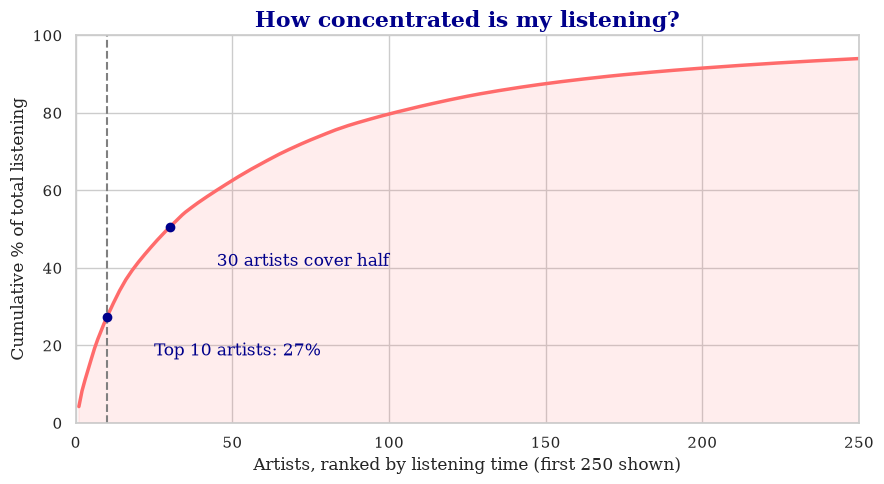

In [24]:
sns.set_theme(font="serif", style="whitegrid")

x = range(1, n_artists + 1)
plt.figure(figsize=(9, 5))
plt.plot(x, cum_share.values * 100, color="#FF6B6B", linewidth=2.5)
plt.fill_between(x, cum_share.values * 100, color="#FF6B6B", alpha=0.12)

# Mark the top 10 and the 50% point
plt.axvline(10, linestyle="--", color="gray")
plt.scatter([10], [cum_share.iloc[9] * 100], color="darkblue", zorder=5)
plt.annotate(f"Top 10 artists: {cum_share.iloc[9]:.0%}",
             (10, cum_share.iloc[9] * 100), xytext=(25, cum_share.iloc[9] * 100 - 10),
             fontsize=12, color="darkblue")

plt.scatter([n50], [cum_share.iloc[n50 - 1] * 100], color="darkblue", zorder=5)
plt.annotate(f"{n50} artists cover half",
             (n50, cum_share.iloc[n50 - 1] * 100), xytext=(n50 + 15, cum_share.iloc[n50 - 1] * 100 - 10),
             fontsize=12, color="darkblue")

plt.xlim(0, 250)
plt.title("How concentrated is my listening?", fontsize=16, fontweight="bold", color="darkblue")
plt.xlabel("Artists, ranked by listening time (first 250 shown)")
plt.ylabel("Cumulative % of total listening")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## Q2. Am I a loyalist or an explorer?

**Definition:** listening share is measured in minutes, using real plays only (30 seconds or more): 16,632 plays across 883 artists. The count is lower than the artists in the raw export because artists I only ever skipped are excluded.

### Finding: a loyal core, a wide edge
- My **top 10 artists** make up **27.4%** of my listening time, and my top artist alone is only 4.2%.
- **30 artists** cover half of everything I listen to, and **102** cover 80%.
- **364 artists (41%)** I played only once, but together they make up just **1.6%** of my listening time.

*The chart above shows the first 250 of 883 artists, because almost all of the curve happens there.*

**Takeaway:** I try a lot of new artists, but most of my time goes to a core of a few dozen favorites. I'm an explorer with a loyal core.

  # Q3. How consistently do I listen?
 i) What are my longest streak and longest gap?
Measure: longest runs of listening and non-listening days

In [25]:
days = pd.to_datetime(pd.Series(df_clean["date"].unique())).sort_values()
all_days = pd.date_range(days.min(), days.max(), freq="D")
listened = pd.Series(all_days.isin(days), index=all_days)

# Split the year into runs of consecutive listening days and non-listening days
run_id = (listened != listened.shift()).cumsum()
runs = listened.groupby(run_id).agg(["first", "size"])
streaks = runs[runs["first"]]["size"]
gaps = runs[~runs["first"]]["size"]

print(f"Days in window: {len(all_days)}")
print(f"Days I listened: {int(listened.sum())} ({listened.mean():.1%})")
print(f"Days with no listening: {int((~listened).sum())}")

print(f"\nLongest streak: {streaks.max()} days")
print(f"Number of streaks: {len(streaks)}")
print(f"Average streak: {streaks.mean():.1f} days")

print(f"\nLongest gap: {gaps.max() if len(gaps) else 0} days")
print(f"Number of gaps: {len(gaps)}")
print("Gap lengths (days):", sorted(gaps.tolist(), reverse=True))

Days in window: 366
Days I listened: 356 (97.3%)
Days with no listening: 10

Longest streak: 157 days
Number of streaks: 10
Average streak: 35.6 days

Longest gap: 2 days
Number of gaps: 9
Gap lengths (days): [2, 1, 1, 1, 1, 1, 1, 1, 1]


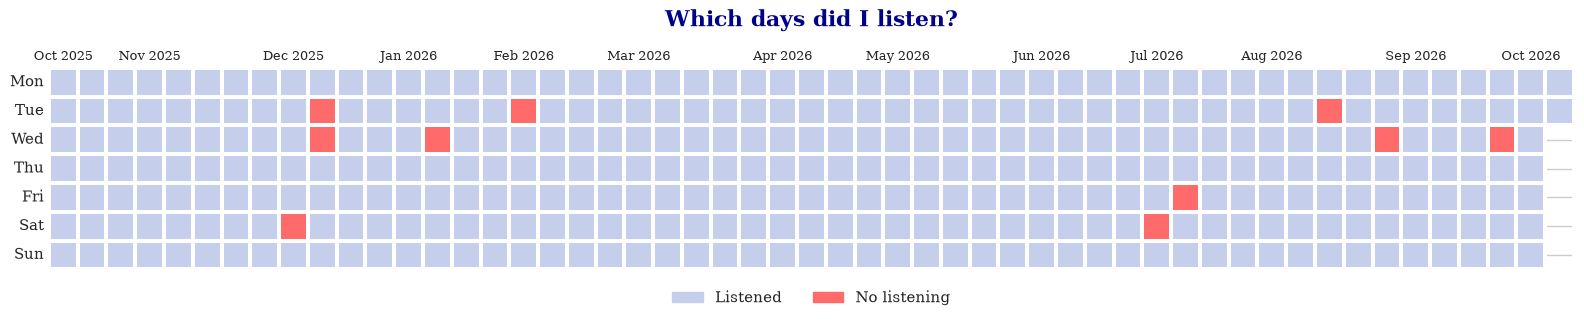

In [26]:


start = all_days[0] - pd.Timedelta(days=all_days[0].weekday())   # back up to that week's Monday
week = (all_days - start).days // 7
dow = all_days.dayofweek

grid = np.full((7, week.max() + 1), np.nan)   # blank cells = outside the window
grid[dow, week] = listened.values.astype(float)

fig, ax = plt.subplots(figsize=(16, 3.8))
sns.heatmap(grid, cmap=ListedColormap(["#FF6B6B", "#C5CEEB"]), vmin=0, vmax=1,
            cbar=False, linewidths=1.5, linecolor="white", square=True,
            xticklabels=False, yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], ax=ax)

# Month labels along the top
month_starts = all_days[all_days.day == 1].insert(0, all_days[0])
ax.set_xticks(((month_starts - start).days // 7) + 0.5)
ax.set_xticklabels(month_starts.strftime("%b %Y"), rotation=0, fontsize=9)
ax.xaxis.tick_top()
ax.tick_params(length=0)

ax.legend(handles=[Patch(color="#C5CEEB", label="Listened"), Patch(color="#FF6B6B", label="No listening")],
          loc="lower center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
ax.set_title("Which days did I listen?", fontsize=16, fontweight="bold", color="darkblue", pad=30)
plt.tight_layout()
plt.show()

## Q3. How consistently do I listen?

**Definition:** a "listening day" is a day with at least one real play (30 seconds or more), in India time. A streak is a run of consecutive listening days, and a gap is a run of days with no real listening. The window is 366 days.

### Finding: listening is close to a daily habit
- I listened on **356 of 366 days (97.3%)**.
- My **longest streak was 157 days**. Across 10 streaks the average is 35.6 days, or about 22 days if the longest one is excluded.
- I never went more than **2 days** without listening, and 8 of my 9 gaps were a single day.

**Takeaway:** my listening is extremely consistent. A day off is rare, and when it happens it's usually just one.

 # Q4. How often does my listening pattern change, and what stays constant?

i) How much does my top 10 artists change month to month?
    Measure: overlap between one month’s top 10 and the next, with the artists that appear in most months noted as what stays constant
   
ii) How adventurous am I?
    Measure: share of each month’s artists I had never played before

In [27]:
months = sorted(df_clean["month"].unique())

In [28]:
monthly_minutes = df_clean.groupby(["month", "artistName"])["minutes"].sum()
top10 = {m: set(monthly_minutes[m].nlargest(10).index) for m in months}


In [29]:
overlap = pd.Series({months[i + 1]: len(top10[months[i]] & top10[months[i + 1]])
                     for i in range(len(months) - 1)})
print("Top-10 overlap with the previous month (out of 10):")
print(overlap.to_string())
print(f"\nAverage overlap (excluding the 6-day last month): {overlap.iloc[:-1].mean():.1f} of 10")


Top-10 overlap with the previous month (out of 10):
2025-11    5
2025-12    4
2026-01    6
2026-02    4
2026-03    7
2026-04    4
2026-05    5
2026-06    1
2026-07    5
2026-08    3
2026-09    6
2026-10    4

Average overlap (excluding the 6-day last month): 4.5 of 10


In [30]:
months_in_top10 = pd.Series([a for m in months for a in top10[m]]).value_counts()
print(f"\nArtists who made a monthly top 10 at least once: {len(months_in_top10)}")
print(f"Artists in the top 10 for more than half of the {len(months)} months: {(months_in_top10 > len(months) / 2).sum()}")
print(f"Most months any single artist made the top 10: {months_in_top10.max()}")


Artists who made a monthly top 10 at least once: 55
Artists in the top 10 for more than half of the 13 months: 3
Most months any single artist made the top 10: 7


In [31]:
seen = set()
rows = []
for m in months:
    this = df_clean[df_clean["month"] == m]
    artists = set(this["artistName"])
    new = artists - seen
    new_minutes = this.loc[this["artistName"].isin(new), "minutes"].sum()
    rows.append({"month": m, "artists": len(artists), "new_artists": len(new),
                 "share_new_artists": len(new) / len(artists),
                 "share_minutes_on_new": new_minutes / this["minutes"].sum()})
    seen |= artists
adv = pd.DataFrame(rows).set_index("month")
print("\n", adv.round(3))


          artists  new_artists  share_new_artists  share_minutes_on_new
month                                                                 
2025-10      214          214              1.000                 1.000
2025-11      140           48              0.343                 0.196
2025-12      134           52              0.388                 0.214
2026-01      145           38              0.262                 0.093
2026-02      155           58              0.374                 0.101
2026-03      209           78              0.373                 0.142
2026-04      294           99              0.337                 0.153
2026-05      273           68              0.249                 0.104
2026-06      257           73              0.284                 0.202
2026-07      240           63              0.262                 0.075
2026-08      233           52              0.223                 0.094
2026-09      171           35              0.205                 0.064
2026

# Q4 i chart, top-10 overlap by month

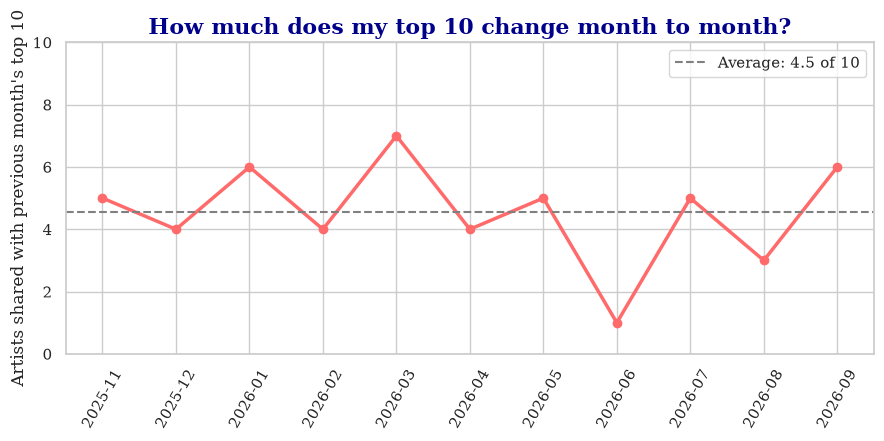

In [32]:
sns.set_theme(font="serif", style="whitegrid")

plot_overlap = overlap.iloc[:-1]   # the last month has only 6 days, so it's left out
plt.figure(figsize=(9, 4.5))
plt.plot(plot_overlap.index, plot_overlap.values, marker="o", color="#FF6B6B", linewidth=2.5)
plt.axhline(plot_overlap.mean(), linestyle="--", color="gray",
            label=f"Average: {plot_overlap.mean():.1f} of 10")
plt.title("How much does my top 10 change month to month?", fontsize=16, fontweight="bold", color="darkblue")
plt.ylabel("Artists shared with previous month's top 10")
plt.ylim(0, 10)
plt.xticks(rotation=60)
plt.legend()
plt.tight_layout()
plt.show()

# Q4 ii chart, how adventurous am I

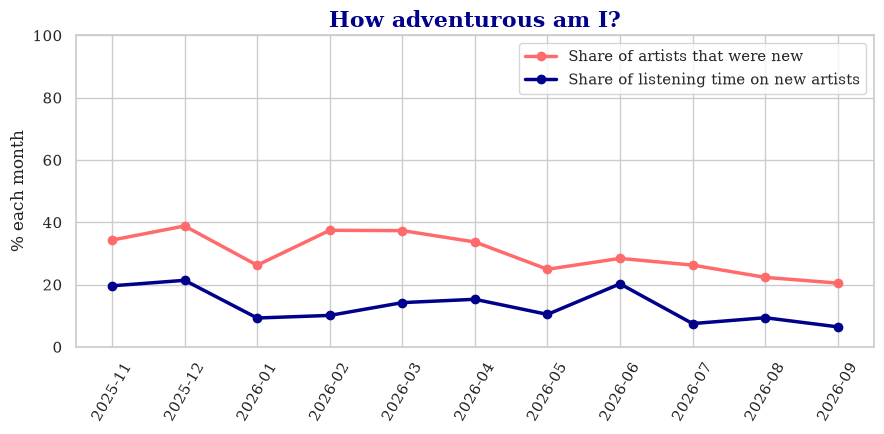

In [33]:
sns.set_theme(font="serif", style="whitegrid")

plot_adv = adv.iloc[1:-1]   # skip the baseline month (everything is new) and the 6-day last month
plt.figure(figsize=(9, 4.5))
plt.plot(plot_adv.index, plot_adv["share_new_artists"] * 100, marker="o", color="#FF6B6B",
         linewidth=2.5, label="Share of artists that were new")
plt.plot(plot_adv.index, plot_adv["share_minutes_on_new"] * 100, marker="o", color="darkblue",
         linewidth=2.5, label="Share of listening time on new artists")
plt.title("How adventurous am I?", fontsize=16, fontweight="bold", color="darkblue")
plt.ylabel("% each month")
plt.ylim(0, 100)
plt.xticks(rotation=60)
plt.legend()
plt.tight_layout()
plt.show()

## Q4. How often does my listening pattern change, and what stays constant?

**Definition:** a month's top 10 is its 10 most-listened artists by minutes (real plays only). An artist is "new" in a month if I hadn't played them in any earlier month of this data. October 2025 is the baseline month, so comparisons start in November. October 2026 has only 6 days, so it's left out of the charts.

### Finding 1: about half of my top 10 turns over each month
- On average, **4.5 of my top 10 artists** carry over from one month to the next, ranging from 7 (March 2026) to just 1 (June 2026).
- Most months keep a core and change the rest, but June 2026 was close to a full reset.

### Finding 2: I try new artists often, but they get little of my time
- Each month, **about a fifth to a third I play are new**, yet they account for only **about 6 to 21% of my listening time**.
- The share of new artists declines over the year, partly because every artist I've already played stops counting as new.

### What stays constant
- **3 artists** made my monthly top 10 in more than half of the 13 months.
- No artist made it every month. The most any artist managed was **7 of 13 months**.

**Takeaway:** my top artists change a lot from month to month. Only a small core of favorites keeps coming back, and even they drop out about half the time. Most of my listening time still goes to artists I already know, rather than to new ones.


## Conclusion

Putting the four questions together, a year of my Spotify history shows a listener who is **habitual but restless**:

- **I'm consistent.** I listened on 356 of 366 days, with a longest streak of 157 days and never more than 2 days off in a row.
- **I have a loyal core.** 30 artists cover half of my listening time, and my top 10 account for 27%.
- **But I'm picky and curious.** I skip about 30% of the songs I start, and that rate climbed from 17% to a peak of 49% over the year. about a fifth to a third of the artists I play each month are new, though they get only 6 to 21% of my listening time.
- **My top 10 turns over by about half each month**, with only 3 artists making it in more than half of the 13 months.

### Limitations
- One year of data from one listener, so these are descriptions of my own habits, not general claims.
- The basic export has no genre, song length or start time. "New artist" means new within this 12-month window.
- A skip is defined as a play under 30 seconds. The data shows that my skipping increased, not why.
- The first and last months are partial, so they are excluded from month-to-month comparisons where noted.

### Next steps
- Add genre data from an outside source to see how my taste shifts by genre.
- Analyze replay behavior: which songs I repeat in short bursts, and how long those obsessions last.
- Repeat key questions in SQL to compare approaches.